# Тонкий notebook проекта

Выберите `.venv` после `uv sync`. Основная реализация находится только в `src/`. Измените output_dir (configs/default.toml) перед повторным запуском.

,model,cv_macro_f1,cv_macro_f1_std,cv_weighted_f1,cv_balanced_accuracy,cv_seconds
0,RandomForest,0.5228,0.0173,0.5781,0.5245,8.8290
1,SVM_linear,0.5210,0.0203,0.5656,0.5297,16.2274
2,SVM_rbf,0.5177,0.0220,0.5633,0.5267,18.1774
3,LogisticRegression,0.5164,0.0217,0.5606,0.5266,3.5630
4,CategoricalNB,0.4994,0.0198,0.5668,0.4968,0.6223
5,LightGBM,0.4804,0.0212,0.5605,0.4860,4.9776
6,XGBoost,0.4730,0.0193,0.5602,0.4847,7.8347
7,GradientBoosting,0.4652,0.0225,0.5546,0.4787,39.0649
8,CatBoost,0.4506,0.0160,0.5471,0.4737,10.3867
9,DecisionTree,0.4348,0.0135,0.4704,0.4704,1.2151


,precision,recall,f1-score,support
Dropout,0.5132,0.5458,0.5290,284.0000
Enrolled,0.3121,0.3396,0.3253,159.0000
Graduate,0.6659,0.6176,0.6408,442.0000
accuracy,0.5446,0.5446,0.5446,0.5446
macro avg,0.4971,0.5010,0.4984,885.0000
weighted avg,0.5533,0.5446,0.5483,885.0000


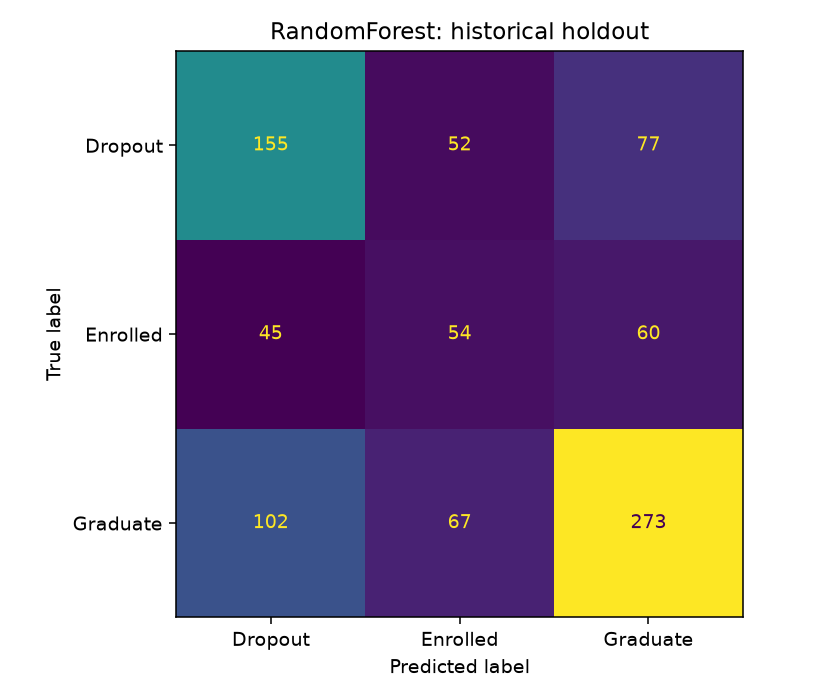

In [3]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from student_outcome.config import read_config
from student_outcome.experiment import run_experiment

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
config = read_config(ROOT / "configs/default.toml")

# True — обучить модели и сохранить новый эксперимент.
# False — прочитать результаты ранее завершённого эксперимента.
RUN_TRAINING = False

RESULTS = config.output_dir

if RUN_TRAINING:
    display(run_experiment(config))

required_files = [
    RESULTS / "comparison.csv",
    RESULTS / "test_metrics.json",
    RESULTS / "test_confusion.png",
]
missing_files = [path for path in required_files if not path.is_file()]

if missing_files:
    missing_names = ", ".join(path.name for path in missing_files)
    raise FileNotFoundError(
        f"В папке {RESULTS} отсутствуют результаты: {missing_names}. "
        "Запустите обучение с RUN_TRAINING = True и новой output_dir "
        "либо укажите папку завершённого эксперимента."
    )

display(pd.read_csv(RESULTS / "comparison.csv").round(4))

result = json.loads((RESULTS / "test_metrics.json").read_text(encoding="utf-8"))
display(pd.DataFrame(result["report"]).T.round(4))
display(Image(filename=str(RESULTS / "test_confusion.png")))